In [17]:
import pandas as pd

In [18]:
import numpy as np

In [19]:
df = pd.read_csv("/content/auto.csv")
df

,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
1,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
2,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
3,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
4,2,?,audi,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
200,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
201,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
202,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [20]:
df.tail()

,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
199,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
200,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
201,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
202,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470
203,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625


In [21]:
df.describe()

,3,88.6,168.8,64.1,48.8,2548,130,9.0,21,27
count,204.000000,204.000000,204.000000,204.000000,204.000000,204.000000,204.000000,204.000000,204.000000,204.000000
mean,0.823529,98.806373,174.075000,65.916667,53.749020,2555.602941,126.892157,10.148137,25.240196,30.769608
std,1.239035,5.994144,12.362123,2.146716,2.424901,521.960820,41.744569,3.981000,6.551513,6.898337
min,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,7.000000,13.000000,16.000000
25%,0.000000,94.500000,166.300000,64.075000,52.000000,2145.000000,97.000000,8.575000,19.000000,25.000000
50%,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,119.500000,9.000000,24.000000,30.000000
75%,2.000000,102.400000,183.200000,66.900000,55.500000,2939.250000,142.000000,9.400000,30.000000,34.500000
max,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,23.000000,49.000000,54.000000


In [22]:
df.dtypes

,0
3,int64
?,object
alfa-romero,object
gas,object
std,object
two,object
convertible,object
rwd,object
front,object
88.6,float64


In [23]:
numeric_columns = df.select_dtypes(include=['int64','float64']).columns.tolist()
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()

In [24]:
print("\n Numeric Columns : ")
print(numeric_columns)


 Numeric Columns : 
['3', '88.6', '168.8', '64.1', '48.8', '2548', '130', '9.0', '21', '27']


In [25]:
print("\n categorical Columns : ")
print(categorical_columns)


 categorical Columns : 
['?', 'alfa-romero', 'gas', 'std', 'two', 'convertible', 'rwd', 'front', 'dohc', 'four', 'mpfi', '3.47', '2.68', '111', '5000', '13495']


In [26]:
#Performing Data Cleaning
#• Handing Missing Data
#• Removing Null data

In [27]:
#Show initial missing value count
print("Missing Values Before Cleaning : ")
print(df.isnull().sum())

Missing Values Before Cleaning : 
3              0
?              0
alfa-romero    0
gas            0
std            0
two            0
convertible    0
rwd            0
front          0
88.6           0
168.8          0
64.1           0
48.8           0
2548           0
dohc           0
four           0
130            0
mpfi           0
3.47           0
2.68           0
9.0            0
111            0
5000           0
21             0
27             0
13495          0
dtype: int64


In [28]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

columns = ['symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration',
           'num-of-doors', 'body-style', 'drive-wheels', 'engine-location',
           'wheel-base', 'length', 'width', 'height', 'curb-weight',
           'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system',
           'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm',
           'city-mpg', 'highway-mpg', 'price']

df = pd.read_csv("/content/auto.csv", header=None, names=columns, na_values='?')

# Convert horsepower to numeric and fill missing with median
df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce')
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())

# Select numeric columns (mpg -> city-mpg, displacement -> engine-size, weight -> curb-weight)
X = df[['city-mpg', 'engine-size', 'horsepower', 'curb-weight', 'highway-mpg', 'wheel-base']]

# Rescale data
scaler = MinMaxScaler()
rescaled_data = scaler.fit_transform(X)

# Display result
print(rescaled_data)

[[0.22222222 0.26037736 0.2625     0.41117145 0.28947368 0.05830904]
 [0.22222222 0.26037736 0.2625     0.41117145 0.28947368 0.05830904]
 [0.16666667 0.34339623 0.44166667 0.51784329 0.26315789 0.2303207 ]
 ...
 [0.13888889 0.42264151 0.35833333 0.59115593 0.18421053 0.65597668]
 [0.36111111 0.31698113 0.24166667 0.67067494 0.28947368 0.65597668]
 [0.16666667 0.30188679 0.275      0.61055081 0.23684211 0.65597668]]


In [29]:
from sklearn.preprocessing import LabelEncoder

# Create LabelEncoder object
encoder = LabelEncoder()

# Encoder categorical column
df['make'] = encoder.fit_transform(df['make'])

# Display encoder data
print(df[['make']].head())

   make
0     0
1     0
2     0
3     1
4     1


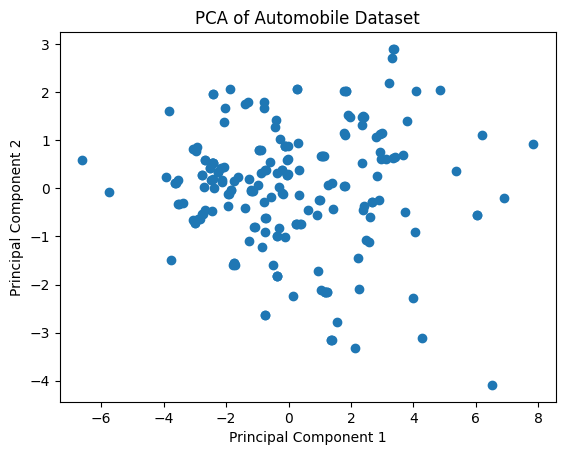

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Select numeric features
X = df[['wheel-base', 'length', 'width', 'height', 'curb-weight',
        'engine-size', 'horsepower', 'city-mpg', 'highway-mpg']]

# Handle missing values
X = X.fillna(X.mean())

# Standardize data
X_scaled = StandardScaler().fit_transform(X)

# Apply PCA
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

# Plot
plt.scatter(principal_components[:, 0], principal_components[:, 1])
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Automobile Dataset")
plt.show()

In [ ]:
+++++